We plot $V_{00}^{sp}$ 

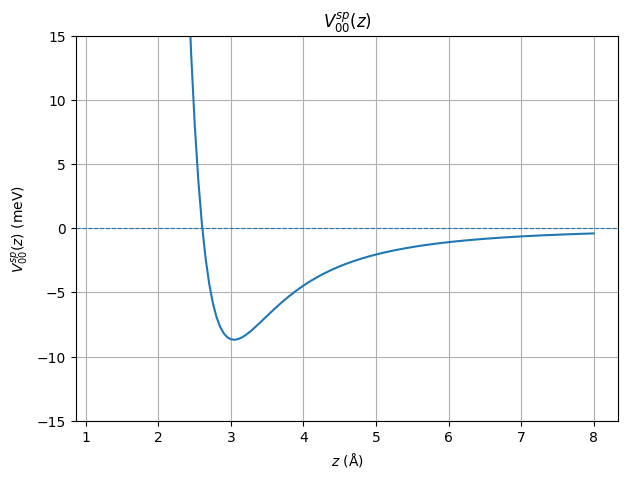

In [51]:
from scipy.special import j0
#j0(0) = 1, check compelte 
from scipy.integrate import quad
import numpy as np
import math
from scipy.special import jn_zeros 

#define our cosntants# 
a = 2.84 #Angstrom 
A_Li = 650.9 * 1000   # meV
A_F  = 4408  * 1000   # meV
b_Li = 5.092 #1/Angstrom
b_F = 4.435 #1/Angstrom
C6_Li = 120 #meV.Angstrom^6
C6_F = 4425 #meV.Angstrom^6
pi = math.pi

#define the atom ion pair potentital
def V_pair(rho, A, b, C6): #eq 3.18 in paper
    series = 0 # we will put this sum in our full expression
    k = 0
    while k < 7:
        series += (math.pow(b*rho,k)/math.factorial(k))*math.exp(-b*rho)
        k += 1 

        
    answer = A*math.exp(-b*rho) - (1-series)*(C6/math.pow(rho,6))
    return answer

#print(V_pair(3.0, A_Li, b_Li, C6_Li)) Gives -0.012466711493751198 meV Reasonable 
#print(V_pair(3.0, A_F, b_F, C6_F)) Gives 1.4056686607741486 meV Reasonable

#define conveniant wrappers 
def V_Li(rho):
    return V_pair(rho, A_Li, b_Li, C6_Li)

def V_F(rho):
    return V_pair(rho, A_F, b_F, C6_F)

def G_mag(m,n): #magnitude of reciprocal lattice vector
    vector = (2 * pi / a) * math.sqrt(math.pow(m,2) + math.pow(n,2))
    return vector

    #let's compute V_{00}
    #Define the domain of our calculation 
z_values = np.arange(1.2, 8.05, 0.05)
V00_sp_values = []

R_max = 80.0

for z in z_values:
    s = 1
    integral_00 = 0

    while s < 3:
        l = 1   # reset l for each ion type

        while l < 11: #compute over first 10 layers as done in Celli. I noticed 5 is enough. 
            z_ls = -(l - 1) * a / math.sqrt(2)

            def integrand(R):
                rho = math.sqrt(R**2 + (z - z_ls)**2)

                if s == 1: #lithium!
                    return R * V_Li(rho)

                if s == 2: #Fluorine 
                    return R * V_F(rho)

            value, error = quad(integrand, 0, R_max)

            integral_00 += value

            l += 1

        s += 1

    V00 = (2 * pi / a**2) * integral_00
    V00_sp_values.append(V00)
    
    import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(z_values, V00_sp_values, label=r"$V_{00}^{sp}(z)$")


plt.axhline(0, linestyle="--", linewidth=0.8)

plt.xlabel(r"$z$ ($\mathrm{\AA}$)")
plt.ylabel(r"$V_{00}^{sp}(z)$ (meV)")
plt.title(r"$V_{00}^{sp}(z)$")
plt.ylim(-15, 15)
plt.grid(True)

plt.show()
    










The following are the contributions to $V_{00}^{sp}$ We see the summation from l equal to 1 to l equal to 3 is sufficient. Higher terms will have minimal influence $V_{00}^{sp}(Z)$

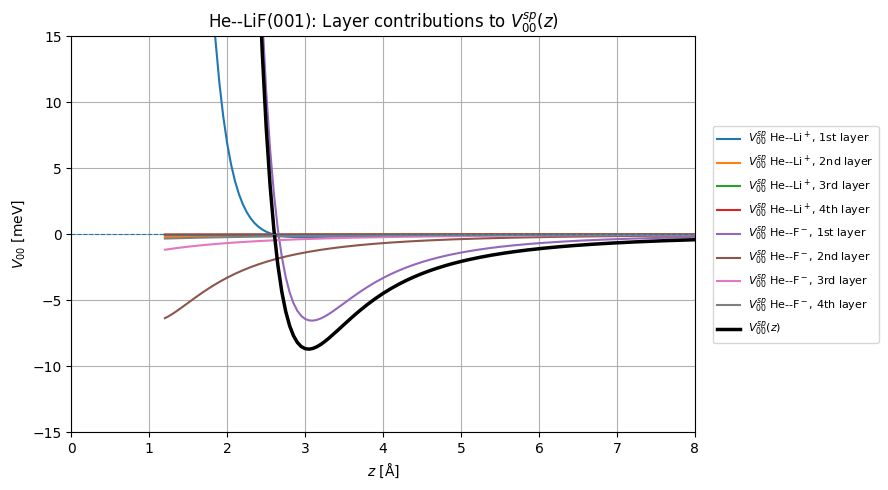

In [52]:
def V00_sp_single_layer(z, ion, l):
    z_ls = -(l - 1) * a / math.sqrt(2)

    def integrand(R):
        rho = math.sqrt(R**2 + (z - z_ls)**2)

        if ion == "Li":
            return R * V_Li(rho)

        if ion == "F":
            return R * V_F(rho)

    value, error = quad(integrand, 0, R_max)

    return (2 * pi / a**2) * value
V00_sp_Li_1st = []
V00_sp_F_1st = []
V00_sp_F_2nd = []
V00_sp_Li_2nd = []
V00_sp_Li_3rd = []
V00_sp_F_3rd = []
V00_sp_Li_4th = []
V00_sp_F_4th = []
V00_sp_Li_5th = []
V00_sp_F_5th = []

for z in z_values:
    V00_sp_Li_1st.append(V00_sp_single_layer(z, "Li", 1))
    V00_sp_Li_2nd.append(V00_sp_single_layer(z, "Li", 2))
    V00_sp_Li_3rd.append(V00_sp_single_layer(z, "Li", 3))
    V00_sp_Li_4th.append(V00_sp_single_layer(z, "Li", 4))
    V00_sp_F_1st.append(V00_sp_single_layer(z, "F", 1))
    V00_sp_F_2nd.append(V00_sp_single_layer(z, "F", 2))
    V00_sp_F_3rd.append(V00_sp_single_layer(z, "F", 3))
    V00_sp_F_4th.append(V00_sp_single_layer(z, "F", 4))
    
    
plt.figure(figsize=(9, 5))

plt.plot(z_values, V00_sp_Li_1st, label=r"$V_{00}^{sp}$ He--Li$^+$, 1st layer")
plt.plot(z_values, V00_sp_Li_2nd, label=r"$V_{00}^{sp}$ He--Li$^+$, 2nd layer")
plt.plot(z_values, V00_sp_Li_3rd, label=r"$V_{00}^{sp}$ He--Li$^+$, 3rd layer")
plt.plot(z_values, V00_sp_Li_4th, label=r"$V_{00}^{sp}$ He--Li$^+$, 4th layer")


plt.plot(z_values, V00_sp_F_1st, label=r"$V_{00}^{sp}$ He--F$^-$, 1st layer")
plt.plot(z_values, V00_sp_F_2nd, label=r"$V_{00}^{sp}$ He--F$^-$, 2nd layer")
plt.plot(z_values, V00_sp_F_3rd, label=r"$V_{00}^{sp}$ He--F$^-$, 3rd layer")
plt.plot(z_values, V00_sp_F_4th, label=r"$V_{00}^{sp}$ He--F$^-$, 4th layer")


plt.plot(
    z_values,
    V00_sp_values,
    color="black",
    linewidth=2.5,
    label=r"$V_{00}^{sp}(z)$"
)

plt.axhline(0, linewidth=0.8, linestyle="--")

plt.xlabel(r"$z$ [$\mathrm{\AA}$]")
plt.ylabel(r"$V_{00}$ [meV]")
plt.title(r"He--LiF(001): Layer contributions to $V_{00}^{sp}(z)$")

plt.ylim(-15, 15)
plt.xlim(0, 8)

plt.grid(True)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8
)

plt.tight_layout()
plt.show()     

We now wish to plot the components $V_{mn}^{sp}(z)$. A possible numerical issue is that the radial integral contains a cylindrical Bessel function, of the form

$
J_0(G_{mn}R),
$

where $G_{mn}=|\mathbf{G}_{mn}|$. Since $J_0(G_{mn}R)$ oscillates and changes sign, directly integrating over a large radial range can lead to numerical cancellation errors. To make the integration more stable, we can split the radial integral into intervals bounded by consecutive zeros of the Bessel function.
At the moment we don't seem to be ecountering issues integrating over the bessel functions. 

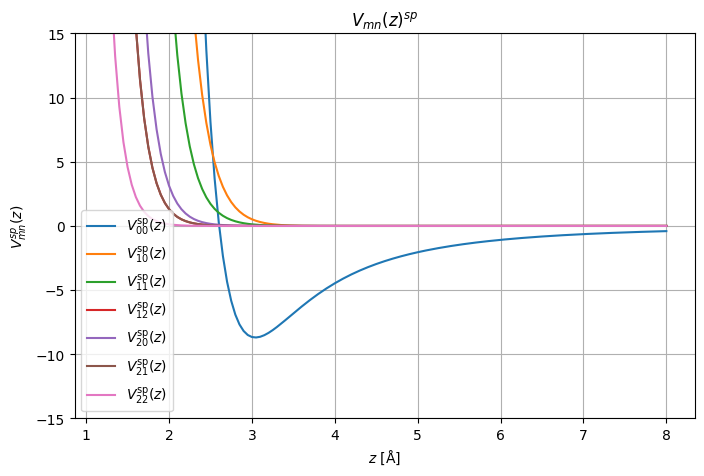

In [53]:
#z_values = np.arange(1.2, 8.05, 0.05)

R_max = 80.0  # Angstrom
#cap Gmn at 22
m_max = 3 
n_max = 3

Vmn_sp_dict = {}
Vmn_sp_dict[(0, 0)] = np.array(V00_sp_values)

for m in range(1, m_max):
    for n in range(0, n_max):

        Gmn = G_mag(m, n)  # magnitude of reciprocal lattice vector G_mn

        Vmn_sp_values = []

        for z in z_values:

            integral_mn = 0.0

            for s in range(1,3):      # s = 1 Li, s = 2 F
                for l in range(1, 3):  # l = 1, 2

                    z_ls = -(l - 1) * a / math.sqrt(2)

                    def integrand_mn(R):
                        rho = math.sqrt(R**2 + (z - z_ls)**2)

                        if s == 1:
                            V = V_Li(rho)
                        else:
                            V = V_F(rho)

                        return R * V * j0(Gmn * R)

                    value, error = quad(integrand_mn, 0, R_max)

                    integral_mn += value

            Vmn_sp = (2 * pi / a**2) * integral_mn
            Vmn_sp_values.append(Vmn_sp)

        Vmn_sp_dict[(m, n)] = np.array(Vmn_sp_values)
        

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for (m, n), Vmn_sp_values in sorted(Vmn_sp_dict.items()):
    plt.plot(
        z_values,
        Vmn_sp_values,
        label=fr"$V_{{{m}{n}}}^{{\mathrm{{sp}}}}(z)$"
    )

plt.xlabel(r"$z$ [$\mathrm{\AA}$]")
plt.ylabel(r"$V_{mn}^{sp}(z)$")
plt.title(r"$V_{mn}(z)^{sp}$")

plt.ylim(-15, 15)   # y-axis range

plt.legend()
plt.grid(True)
plt.show()
            
            

            

The above image is nearly in agreement with Figure 3 by Celli et al. I We need to still add Vid to get figure 3. Or Celli et al, mislabelled

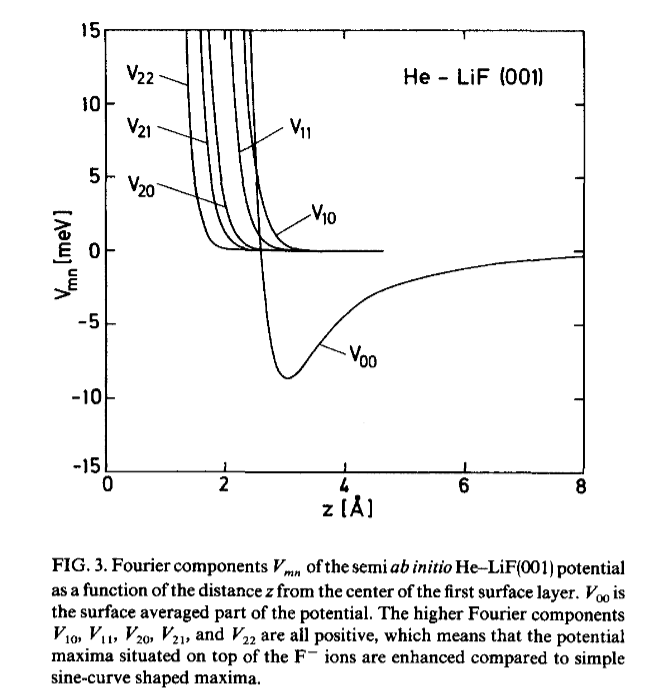

The code below includes the -1 factor in eq:3.6 

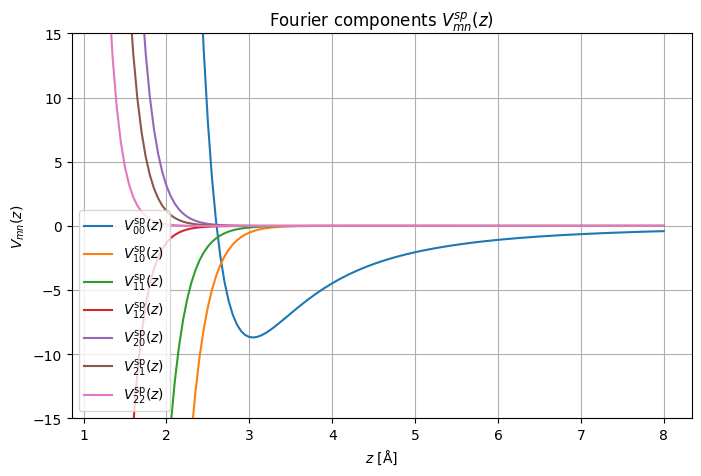

In [54]:
#z_values = np.arange(1.2, 8.05, 0.05)

R_max = 80.0  # Angstrom

m_max = 3
n_max = 3

Vmn_sp_dict = {}
Vmn_sp_dict[(0, 0)] = np.array(V00_sp_values)

for m in range(1, m_max):
    for n in range(0, n_max):

        Gmn = G_mag(m, n)  # magnitude of reciprocal lattice vector G_mn

        Vmn_sp_values = []

        for z in z_values:

            integral_mn = 0.0

            for s in range(1, 3):       # s = 1 Li, s = 2 F
                for l in range(1, 3):   # l = 1, 2. Layers 1 and 2 is all we need for the calculaion! Surface effect. 

                    z_ls = -(l - 1) * a / math.sqrt(2)

                    # Lattice/basis phase factor from Celli Eq. (3.6)
                    phase_factor = (-1)**(m + n * (l + s - 1))

                    def integrand_mn(R):
                        rho = math.sqrt(R**2 + (z - z_ls)**2)

                        if s == 1:
                            V = V_Li(rho)

                        if s == 2:
                            V = V_F(rho)

                        return R * V * j0(Gmn * R)

                    value, error = quad(integrand_mn, 0, R_max)

                    integral_mn += phase_factor * value

            Vmn_sp = (2 * pi / a**2) * integral_mn
            Vmn_sp_values.append(Vmn_sp)

        Vmn_sp_dict[(m, n)] = np.array(Vmn_sp_values)



plt.figure(figsize=(8, 5))

for (m, n), Vmn_values in sorted(Vmn_sp_dict.items()):
    plt.plot(
        z_values,
        Vmn_values,
        label=fr"$V_{{{m}{n}}}^{{\mathrm{{sp}}}}(z)$"
    )

plt.xlabel(r"$z$ [$\mathrm{\AA}$]")
plt.ylabel(r"$V_{mn}(z)$")
plt.title(r"Fourier components $V_{mn}^{sp}(z)$")

plt.ylim(-15, 15)

plt.legend()
plt.grid(True)
plt.show()
            

We now wish to replicate Figure 4 in the paper by Celli et al. Note 
The induced-dipole contribution in Equation (3.13) has the form

$$
V^{id}(\mathbf{r}) \propto -e^{-4\pi z/a}\left(1+\cos\frac{2\pi x}{a}\cos\frac{2\pi y}{a}\right).
$$

The $V^{id}_{00}(z)$ component is the laterally averaged part of this potential over one surface unit cell. Physically, this is the smooth background attraction felt by the helium atom after averaging over all lateral positions $(x,y)$. The constant term contributes to this average, while the oscillatory cosine term represents the lateral corrugation of the surface potential and averages to zero over a unit cell.

Therefore, for the $00$ Fourier component, only the constant part of Equation (3.13) contributes:

$$
V^{id}_{00}(z)
=

-\frac{64\pi^2\alpha e^2}{a^4(1+e^{-\pi\sqrt{2}})^2}
e^{-4\pi z/a}.
$$

T


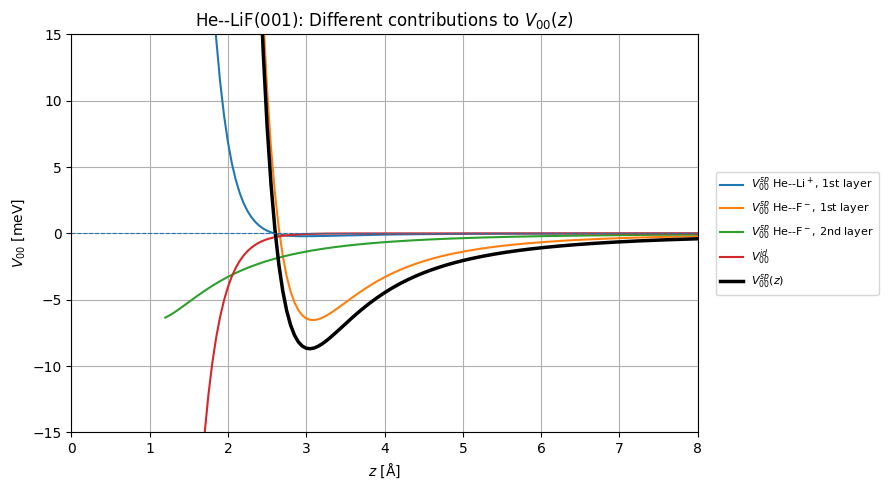

In [55]:
alpha = 0.206 #angstrom^3, the polarizability of the Helium atom. 
e_squared = 14399.6  # meV Angstrom; Coulomb factor e^2/(4*pi*epsilon_0) = 14.3996 eV Angstrom = 14399.6 meV Angstrom

#z_values = np.arange(1.2, 8.05, 0.05)
Vid_00_values = []
for z in z_values:
    Vid_00 = - ( (64*math.pow(pi,2)*alpha*e_squared) / (math.pow(a,4) * math.pow(1+math.exp(-pi*math.sqrt(2)),2)) ) * math.exp(-4*pi*z / a)
    Vid_00_values.append(Vid_00)

plt.figure(figsize=(9, 5))

plt.plot(z_values, V00_sp_Li_1st, label=r"$V_{00}^{sp}$ He--Li$^+$, 1st layer")
plt.plot(z_values, V00_sp_F_1st, label=r"$V_{00}^{sp}$ He--F$^-$, 1st layer")
plt.plot(z_values, V00_sp_F_2nd, label=r"$V_{00}^{sp}$ He--F$^-$, 2nd layer")
plt.plot(z_values, Vid_00_values, label=r"$V_{00}^{id}$")


plt.plot(
    z_values,
    V00_sp_values,
    color="black",
    linewidth=2.5,
    label=r"$V_{00}^{sp}(z)$"
)

plt.axhline(0, linewidth=0.8, linestyle="--")

plt.xlabel(r"$z$ [$\mathrm{\AA}$]")
plt.ylabel(r"$V_{00}$ [meV]")
plt.title(r"He--LiF(001): Different contributions to $V_{00}(z)$")

plt.ylim(-15, 15)
plt.xlim(0, 8)

plt.grid(True)

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8
)

plt.tight_layout()
plt.show()     
    
    

Matches Figure 4! Note I also included V00(z) (black line) that figure 4 does not

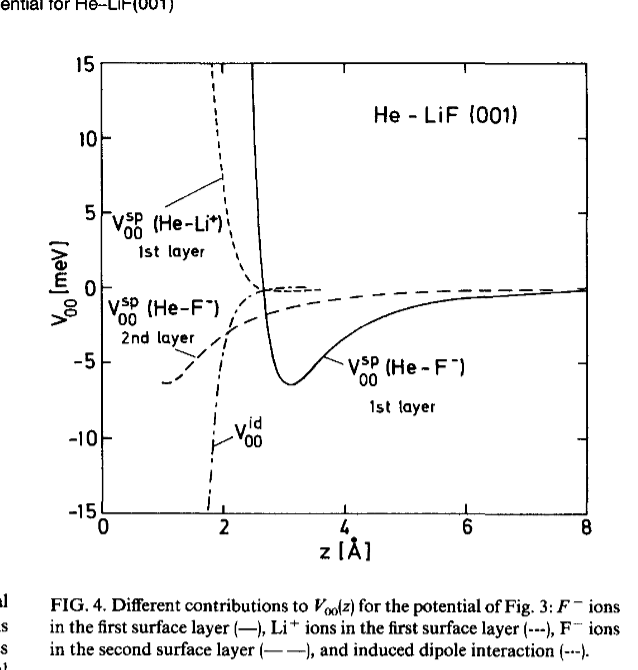

We now wish to replicate figure 5
The surface avg potentital. We can get from above, V_00 =  $V^{id}_{00}$ and $V^{sp}_{00}$
The following image will be useful for getting the next two curves.

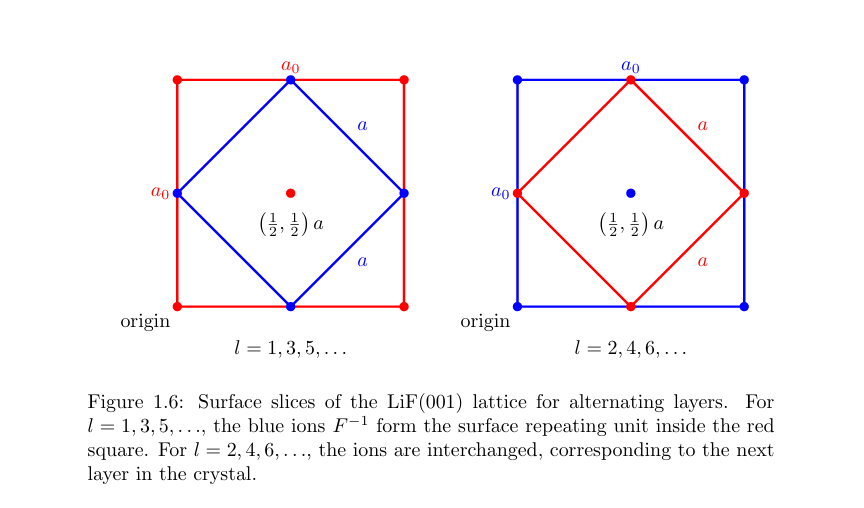


To obtain the curves labelled “above $Li^+$” and “above $F^-$”, the real-space potential must be reconstructed from the Fourier components,

$$
V^{sp}(x,y,z)=\sum_{mn}V_{mn}^{sp}(z)e^{i\mathbf{G}_{mn}\cdot\mathbf{R}},
$$

where $\mathbf{R}=(x,y)$ is the lateral position of the helium atom. Physically, the nonzero Fourier components describe the lateral corrugation of the surface potential. 

For odd surface layers, taking $Li^+$ s=1 to lie at the origin (consider the figure above if you need to comprehend this)

$$
\mathbf{R}_{\mathrm{Li}}=(0,0).
$$

 A neighbouring $F^-$ site can be represented by

$$
\mathbf{R}_{\mathrm{F}}=\left(\frac{a}{2},0\right),
$$


The induced-dipole part should also be evaluated differently depending on the curve. For the surface average, only the $00$ component is used:

$$
V_{00}^{id}(z).
$$

For the site-specific curves, the full real-space induced-dipole expression should be used:

$$
V^{id}(x,y,z)
\propto
-e^{-4\pi z/a}
\left(
1+\cos\frac{2\pi x}{a}\cos\frac{2\pi y}{a}
\right).
$$

Therefore the three curves in Figure 5(a) correspond to

$$
V_{00}(z)=V_{00}^{sp}(z)+V_{00}^{id}(z),
$$

$$
V_{\mathrm{above\ Li}}(z) = V^{sp}(0,0,z)+V^{id}(0,0,z),
$$

and

$$
V_{\mathrm{above\ F}}(z) = V^{sp}\left(\frac{a}{2},0,z\right) + V^{id}\left(\frac{a}{2},0,z\right).
$$
$$
V^{id}\left(\frac{a}{2},0,z\right) = 0 
$$
Hence, 
$$
V_{\mathrm{above\ F}}(z) = V^{sp}\left(\frac{a}{2},0,z\right)
$$


Thus we solve 
For the site-specific curves, 

$$
\begin{aligned}
V_{\mathrm{above\ Li}}(z)
&=
\frac{2\pi}{a^2}
\sum_{m,n}
\sum_{l,s}
(-1)^{(m+n)(l+s-1)}
\int_0^\infty dR'\,R'\,
v^{(s)}\!\left(\sqrt{R'^2+(z-z_{ls})^2}\right)
J_0\!\left(\frac{2\pi R'}{a}\sqrt{m^2+n^2}\right)
\\
&\quad
-
\frac{128\pi^2\alpha e^2}
{a^4\left(1+e^{-\pi\sqrt{2}}\right)^2}
e^{-4\pi z/a}.
\end{aligned}
$$

Where we can simplify further 


$$
-
\frac{128\pi^2\alpha e^2}
{a^4\left(1+e^{-\pi\sqrt{2}}\right)^2}
e^{-4\pi z/a} = 
2V_{00}^{id}
$$

For the neighbouring $F^-$ site we get. our expoential $e^{iG.R}$ evaluated to $(-1)^m$ thus we can simplify

$$
\begin{aligned}
V_{\mathrm{above\ F}}(z)
&=
\frac{2\pi}{a^2}
\sum_{m,n}
\sum_{l,s}
(-1)^{(m + (m + n) (l + s - 1))}
\int_0^\infty dR'\,R'\,
v^{(s)}\!\left(\sqrt{R'^2+(z-z_{ls})^2}\right)
J_0\!\left(\frac{2\pi R'}{a}\sqrt{m^2+n^2}\right).
\end{aligned}
$$




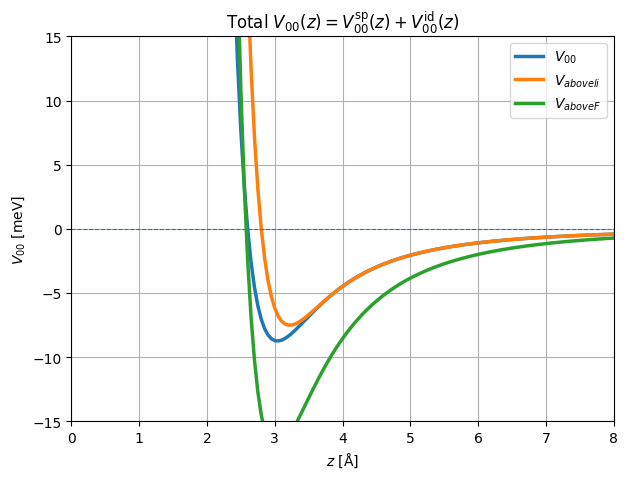

In [56]:
V00_sp_values = np.array(V00_sp_values)
Vid_00_values = np.array(Vid_00_values)

V_00 = V00_sp_values + Vid_00_values

#compute potentital above Lithium
#z_values = np.arange(1.2, 8.05, 0.05)

def degeneracy_factor(m, n): #eq 3.19 in celli if you are confused
    """
    Multiplicity from square-lattice symmetry.

    We assume m >= n >= 0.
    """

    if n == 0:
        return 4      # (±m,0), (0,±m)

    if m == n:
        return 4      # (±m,±m)

    return 8          # (±m,±n) and (±n,±m)

R_max = 80.0  # Angstrom

m_max = 3
n_max = 3 #sum Gmn from G00 to G22

Vmn_sp_li = np.array(V00_sp_values) # we are going to add vmn valyes now. 

for m in range(1, m_max):
    for n in range(0, n_max):

        Gmn = G_mag(m, n)  # magnitude of reciprocal lattice vector G_mn

        Vmn_sp_li_values = []
        
        degeneracy = degeneracy_factor(m, n)


        for z in z_values:

            integral_mn = 0.0

            for s in range(1, 3):       # s = 1 Li, s = 2 F
                for l in range(1, 3):   # l = 1, 2. Layers 1 and 2 is all we need for the calculaion! Surface effect. 

                    z_ls = -(l - 1) * a / math.sqrt(2)

                    # Lattice/basis phase factor from Celli Eq. (3.6)
                    phase_factor = (-1)**((m + n) * (l + s - 1))

                    def integrand_mn(R):
                        rho = math.sqrt(R**2 + (z - z_ls)**2)

                        if s == 1:
                            V = V_Li(rho)

                        if s == 2:
                            V = V_F(rho)

                        return R * V * j0(Gmn * R)

                    value, error = quad(integrand_mn, 0, R_max)

                    integral_mn += phase_factor * value

            Vmn_sp = (2 * pi / a**2) * integral_mn
            Vmn_sp_li_values.append(Vmn_sp)

        Vmn_sp_li_values = np.array(Vmn_sp_li_values)
        Vmn_sp_li += degeneracy *Vmn_sp_li_values #update each entry 
        
Vmn_Li = 2*Vid_00_values + Vmn_sp_li

#compute potentital above Fluorine. Unfortuantely we don't simplify our degeracies. In following cells we will. 
Vmn_sp_f = np.array(V00_sp_values) # we are going to add vmn valyes now. 

for m in range(-m_max+1, m_max):
    for n in range(-n_max+1, n_max):

        Gmn = G_mag(m, n)  # magnitude of reciprocal lattice vector G_mn

        Vmn_sp_f_values = []
        


        for z in z_values:

            integral_mn = 0.0

            for s in range(1, 3):       # s = 1 Li, s = 2 F
                for l in range(1, 3):   # l = 1, 2. Layers 1 and 2 is all we need for the calculaion! Surface effect. 

                    z_ls = -(l - 1) * a / math.sqrt(2)

                    # Lattice/basis phase factor from Celli Eq. (3.6)
                    phase_factor = (-1)**(m+(m + n) * (l + s - 1))

                    def integrand_mn(R):
                        rho = math.sqrt(R**2 + (z - z_ls)**2)

                        if s == 1:
                            V = V_Li(rho)

                        if s == 2:
                            V = V_F(rho)

                        return R * V * j0(Gmn * R)

                    value, error = quad(integrand_mn, 0, R_max)

                    integral_mn += phase_factor * value

            Vmn_sp = (2 * pi / a**2) * integral_mn
            Vmn_sp_f_values.append(Vmn_sp)

        Vmn_sp_f_values = np.array(Vmn_sp_f_values)
        Vmn_sp_f += Vmn_sp_f_values #update each entry 

V_above_F = Vmn_sp_f

plt.figure(figsize=(7, 5))

plt.plot(z_values, V_00, label=r"$V_{00}$", linewidth=2.5)
plt.plot(z_values, Vmn_Li, label=r"$V_{above li}$", linewidth=2.5)
plt.plot(z_values, V_above_F, label=r"$V_{above F}$", linewidth=2.5)

plt.axhline(0, linewidth=0.8, linestyle="--")

plt.xlabel(r"$z$ [$\mathrm{\AA}$]")
plt.ylabel(r"$V_{00}$ [meV]")
plt.title(r"Total $V_{00}(z)=V_{00}^{\mathrm{sp}}(z)+V_{00}^{\mathrm{id}}(z)$")

plt.ylim(-15, 15)
plt.xlim(0, 8)

plt.legend()
plt.grid(True)
plt.show()

We have a different plot to figure 5. We are actually looking at the wrong ions. We are getting convergence issues when integrating! In subsequent cells we will integrate over intervals that ensure convergence.  We are also having issues with length of computation... We need to take further advantage of the symmetries of the crystal. We will do so in the next cell and as explained below in the markdown.

We aim to replicate figure 6. We simplify calculations by the symmetries of our crystal. 
## Exploiting the degeneracy simplification

From Equation (3.19) in Celli, the Fourier components related by square-lattice symmetry are equal. For example, components with indices related by sign changes or interchange of $m$ and $n$ have the same magnitude because the radial integral only depends on

$$
G_{mn}=\frac{2\pi}{a}\sqrt{m^2+n^2}.
$$

Therefore, the expensive radial integral only needs to be evaluated once for each independent pair $(m,n)$ with $m\ge n\ge 0$. The remaining symmetry-related terms can then be added through a degeneracy or symmetry factor.

The phase factor appearing in the short-range potential is

$$
(-1)^{(m+n)(l+s-1)} e^{i\mathbf{G}_{mn}\cdot\mathbf{R}}.
$$

For convenience, define

$$
A=l+s-1.
$$

Then the phase factor becomes

$$
(-1)^{(m+n)A} e^{i\mathbf{G}_{mn}\cdot\mathbf{R}}.
$$

Now consider a diagonal cut through the surface, such that

$$
y=x.
$$

Define the lateral coordinate

$$
u=\sqrt{x^2+y^2}.
$$

Since $y=x$, we have

$$
x=y=\frac{u}{\sqrt{2}}.
$$

so

$$
\mathbf{G}_{mn}\cdot\mathbf{R}
=

\frac{2\pi}{a}(mx+ny).
$$

Along the diagonal cut this becomes

$$
\mathbf{G}_{mn}\cdot\mathbf{R}
=

\frac{2\pi u}{a\sqrt{2}}(m+n).
$$

We define

$$
k=\frac{2\pi u}{a\sqrt{2}},
$$

so that

$$
\mathbf{G}_{mn}\cdot\mathbf{R}=(m+n)k.
$$

Therefore, for a given reciprocal lattice vector, the phase factor becomes

$$
(-1)^{(m+n)A}e^{i(m+n)k}.
$$

### Case 1: symmetry set $(m,0)$

Consider the symmetry-equivalent reciprocal lattice vectors

$$
(m,0),\quad (-m,0),\quad (0,m),\quad (0,-m).
$$

These all have the same value of $m^2+n^2$, so the radial integral is the same for each of them. The only difference between these terms is the phase factor. We therefore only need to sum their phase factors.

For these four symmetry-related vectors, the phase factors are

$$
(-1)^{mA}e^{imk}
+
(-1)^{-mA}e^{-imk}
+
(-1)^{mA}e^{imk}
+
(-1)^{-mA}e^{-imk}.
$$

Since $(-1)^{-mA}=(-1)^{mA}$, this becomes

$$
2(-1)^{mA}e^{imk}
+
2(-1)^{mA}e^{-imk}.
$$

equalling 

$$
4(-1)^{mA}\cos(mk).
$$

This corresponds to the code line in the next cell where we have a degeneracy factor

```python
return 4 * (-1)**(m * A) * np.cos(m * k)
```

### Case 2: symmetry set $(m,m)$

Now consider the case where the two indices are equal. The symmetry-related reciprocal lattice vectors are

$$
(m,m),\quad (-m,-m),\quad (m,-m),\quad (-m,m).
$$



For the vector $(m,m)$, we have

$$
p+q=2m,
$$

so its phase is

$$
(-1)^{2mA}e^{i2mk}=e^{i2mk}.
$$

For the vector $(-m,-m)$, we have

$$
p+q=-2m,
$$

so its phase is

$$
(-1)^{-2mA}e^{-i2mk}=e^{-i2mk}.
$$

For the two remaining vectors, $(m,-m)$ and $(-m,m)$, we have

$$
p+q=0,
$$

so each contributes a phase factor of $1$.

Therefore, summing over the four symmetry-related vectors gives


$$
2+2\cos(2mk).
$$


This corresponds to the code line

```python
return 2 + 2 * np.cos(2 * m * k)
```

---

### Case 3: symmetry set $(m,n)$ with $m>n>0$

Finally consider the general case where both indices are nonzero and unequal, with

$$
m>n>0.
$$

The symmetry-related reciprocal lattice vectors are

$$
(m,n),\quad (-m,-n),\quad (m,-n),\quad (-m,n),
$$

and the swapped set

$$
(n,m),\quad (-n,-m),\quad (n,-m),\quad (-n,m).
$$

All eight vectors have the same value of $m^2+n^2$, so the radial integral is the same for each. We therefore only need to sum their phase factors.

For the first group, the possible values of $p+q$ are

$$
m+n,\quad -(m+n),\quad m-n,\quad -(m-n).
$$

The corresponding phase contribution is

$$
2(-1)^{(m+n)A}\cos((m+n)k)
+
2(-1)^{(m-n)A}\cos((m-n)k).
$$

The swapped group gives the same contribution again, so the total symmetry factor is

$$
4(-1)^{(m+n)A}\cos((m+n)k)
+
4(-1)^{(m-n)A}\cos((m-n)k).
$$

This corresponds to the code block

```python
return (
    4 * (-1)**((m + n) * A) * np.cos((m + n) * k)
    +
    4 * (-1)**((m - n) * A) * np.cos((m - n) * k)
)
```



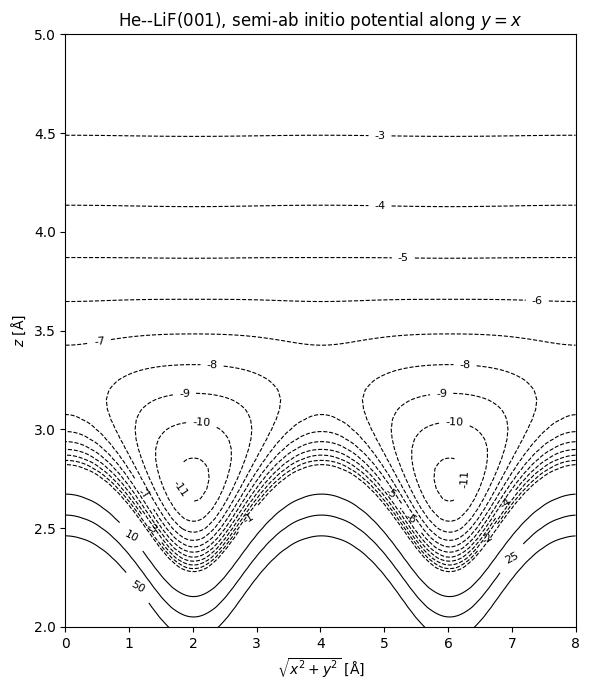

In [57]:
from scipy.special import j0



# ------------------------------------------------------------
# Bessel-zero integration helpers
# ------------------------------------------------------------

def bessel_zero_points_inside(Gmn, R_max, order=0, buffer=5):
    """
    Return zeros of J_0Gmn R) inside 0 < R < R_max.
    These are used as break points for quad to ensure convergence. 
    """

    Gmn = abs(Gmn)

    if np.isclose(Gmn, 0.0): #Bessel function does not oscillate for J(0) = 1. We dont want to break up the integration 
        return []

    x_max = Gmn * R_max #J(Gmn*R_max) we wish to find the zeros of 
    N = int(np.ceil(x_max / np.pi)) + buffer #Number of times to split up our integrand 

    x_zeros = jn_zeros(0, N) #first N zeros of J0​(x).
    x_zeros = x_zeros[x_zeros < x_max] #N should overshoot x zeros and now we trim it. 

    R_zeros = x_zeros / Gmn #J(Gmn*R) = (x) 

    return R_zeros.tolist() #convert our array back to list as quad function deals better with lists


def quad_with_bessel_points(integrand, Gmn, R_max):
    """
    Integrate with quad, splitting at the zeros of J0(Gmn R).
    """

    zero_points = bessel_zero_points_inside(Gmn, R_max)

    value, error = quad(
        integrand,
        0,
        R_max,
        points= zero_points, #tells quad that local difficulties occur at these points. Quad will split the integral accordingly. 
        limit=len(zero_points) + 50  # allow quad enough subintervals for all Bessel-zero break points, plus extra subdivisions for convergence

    )

    return value, error


# ------------------------------------------------------------
# Symmetry factor for diagonal cut y = x. Refer to markdown above if you are confused. 
# ------------------------------------------------------------

def diagonal_symmetry_factor(m, n, l, s, u_values):
    """
    Symmetry-weighted phase factor for the diagonal line y = x.

    The lateral coordinate is
        u = sqrt(x^2 + y^2)

    Along y = x,
        x = u/sqrt(2), y = u/sqrt(2).

    Assumes m >= n >= 0.
    """

    A = l + s - 1
    k = 2 * pi * u_values / (a * math.sqrt(2))

    if n == 0:
        # (±m,0), (0,±m)
        return 4 * (-1)**(m * A) * np.cos(m * k)

    elif m == n:
        # (±m,±m)
        return 2 + 2 * np.cos(2 * m * k)

    else:
        # (±m,±n) and (±n,±m)
        return (
            4 * (-1)**((m + n) * A) * np.cos((m + n) * k)
            +
            4 * (-1)**((m - n) * A) * np.cos((m - n) * k)
        )


# ------------------------------------------------------------
# Grid for Fig. 6(a)-style contour plot
# ------------------------------------------------------------

R_max = 80.0  # Angstrom

m_cut = 2     # includes independent representatives up to G22

u_values = np.linspace(0.0, 8.0, 241)   # horizontal axis: sqrt(x^2 + y^2) same as figure 6 Celli

#z_values = np.arange(1.2, 8.05, 0.05)

U, Z = np.meshgrid(u_values, z_values) 

# We are moving along x = y = u/sqrt(2)
X = U / math.sqrt(2)
Y = U / math.sqrt(2)


# ------------------------------------------------------------
# Start with V00^sp contribution
# ------------------------------------------------------------
#we already solved for V00_sp_Values in a previous cell, they are laterally smeared (no variation). So we repeat the across the U our surface
V_sp_grid = np.repeat(
    V00_sp_values[:, None], #turns our V00_sp_values a column
    len(u_values), #How many times we repeat this column 
    axis=1 #repeats across 
    #axis=0   # down the rows
    #axis=1   # across the columns
)


# ------------------------------------------------------------
# Add nonzero Fourier components of V^sp
# ------------------------------------------------------------

for m in range(1, m_cut + 1):
    for n in range(0, m + 1):


        Gmn = G_mag(m, n)

        for s in range(1, 3):       # s = 1 Li, s = 2 F
            for l in range(1, 3):   # l = 1, 2

                z_ls = -(l - 1) * a / math.sqrt(2)

                I_z_values = []

                for z in z_values:

                    def integrand_mn(R):
                        rho = math.sqrt(R**2 + (z - z_ls)**2)

                        if s == 1:
                            V = V_Li(rho)
                        else:
                            V = V_F(rho)

                        return R * V * j0(Gmn * R)

                    value, error = quad_with_bessel_points(
                        integrand_mn,
                        Gmn,
                        R_max
                    )

                    I_z_values.append(value)

                I_z_values = np.array(I_z_values) 

                symmetry_u_values = diagonal_symmetry_factor(m,n,l,s,u_values)
                   
                #update our V_sp_grid
                V_sp_grid += (
                    (2 * pi / a**2)
                    * I_z_values[:, None] #This turns I_z_values from a 1D array into a column: since it depends only on z
                    * symmetry_u_values[None, :] #This turns symmetry_u_values into a row: depends on k which depends on u. 
                )


# ------------------------------------------------------------
# Add induced-dipole contribution V^id(x,y,z)
# ------------------------------------------------------------
#defined already
#alpha = 0.206   Angstrom^3, helium polarizability
#e_squared = 14399.6  # meV Angstrom; e^2/(4*pi*epsilon_0)

Vid_prefactor = (
    64 * pi**2 * alpha * e_squared
    /
    (a**4 * (1 + math.exp(-pi * math.sqrt(2)))**2)
)

V_id_grid = (
    -Vid_prefactor
    * np.exp(-4 * pi * Z / a)
    * (
        1
        + np.cos(2 * pi * X / a) #x = U/sqrt(2), U is an array of our horizontal values. 
        * np.cos(2 * pi * Y / a) #y = U/sqrt(2)
    )
)

V_grid = V_sp_grid + V_id_grid


# ------------------------------------------------------------
# Contour plot
# ------------------------------------------------------------

plt.figure(figsize=(6, 7))

levels = [-50, -25, -15, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 10, 25, 50] #draws the equipotentital contour lines

cs = plt.contour(
    U,
    Z,
    V_grid,
    levels=levels, #our contour lines as defined above. lines of equipotentital
    colors="black",
    linewidths=0.8
)

plt.clabel(cs, inline=True, fontsize=8, fmt="%g") #labels our contours, %g means general number format.

plt.xlabel(r"$\sqrt{x^2+y^2}$ [$\mathrm{\AA}$]")
plt.ylabel(r"$z$ [$\mathrm{\AA}$]")
plt.title(r"He--LiF(001), semi-ab initio potential along $y=x$")

plt.xlim(0, 8)
plt.ylim(2, 5)

plt.grid(False)

plt.tight_layout()
plt.show()

Same as Figure 6! 

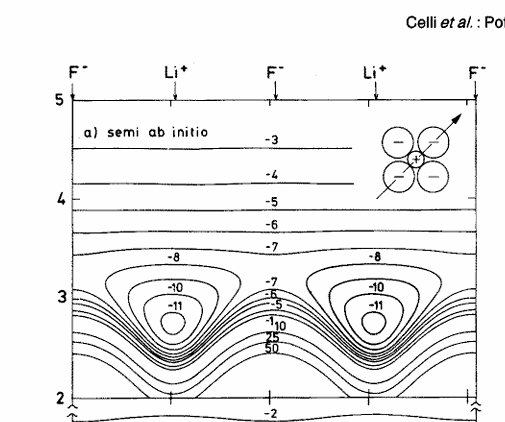

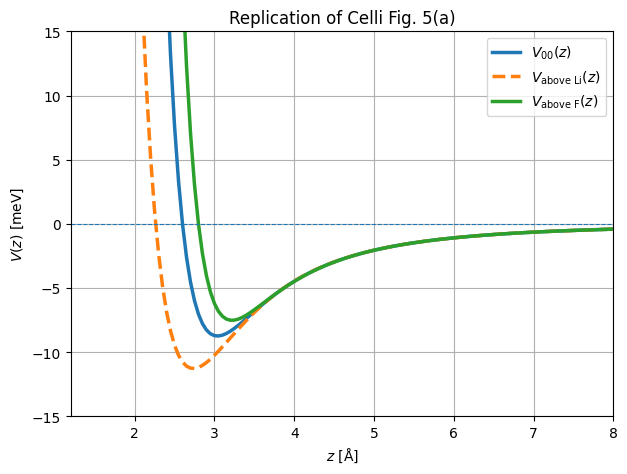

In [59]:
# ------------------------------------------------------------
# Extract Fig. 5-style vertical cuts from the Fig. 6 contour grid
# ------------------------------------------------------------

# u = sqrt(x^2 + y^2) spacing between adjacent ions along y = x = a/sqrt(2)
ion_spacing = a / math.sqrt(2)

# Pick interior ion positions from the contour plot
#F at origin. 
u_Li = ion_spacing        # first Li+ site 1 ion spacing from origin
u_F  = 2 * ion_spacing    # neighbouring F- site, 2 ion spacings from origin



def extract_vertical_cut(V_grid, u_values, u0):
    """
    Extract V(u0,z) from V_grid by interpolating along the u direction.
    V_grid has shape (len(z_contour_values), len(u_values)).
    """

    V_cut = []

    for i in range(V_grid.shape[0]): #loops over each row of V_grid, meaning each $z$ value
        V_cut.append(np.interp(u0, u_values, V_grid[i, :])) #takes the V value at specified u0. So we build a column of V(z) at given u0

    return np.array(V_cut)


# Site-specific cuts from the full semi-ab initio potential grid
V_above_Li_from_grid = extract_vertical_cut(V_grid, u_values, u_Li)
V_above_F_from_grid  = extract_vertical_cut(V_grid, u_values, u_F)




# ------------------------------------------------------------
# Plot Fig. 5(a)-style comparison
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    z_values,
    V_00,
    label=r"$V_{00}(z)$", #we already solved this in a previous cell
    linewidth=2.5
)

plt.plot(
    z_values,
    V_above_Li_from_grid,
    label=r"$V_{\mathrm{above\ Li}}(z)$",
    linewidth=2.5,
    linestyle="--"
)

plt.plot(
    z_values,
    V_above_F_from_grid,
    label=r"$V_{\mathrm{above\ F}}(z)$",
    linewidth=2.5
)

plt.axhline(0, linewidth=0.8, linestyle="--")

plt.xlabel(r"$z$ [$\mathrm{\AA}$]")
plt.ylabel(r"$V(z)$ [meV]")
plt.title(r"Replication of Celli Fig. 5(a)")

plt.ylim(-15, 15)
plt.xlim(np.min(z_values), np.max(z_values))

plt.legend()
plt.grid(True)
plt.show()

Same as Figure 5!

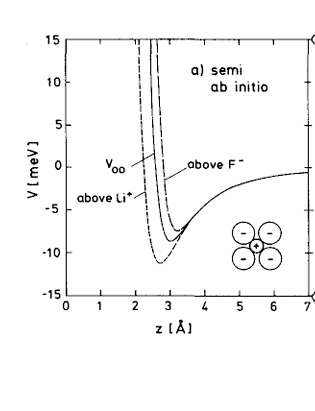